# Hospital Management System: Heart Disease Binary Classification, Regression & Correlation Analysis

**Author:** Dela Patience Korbla (`PUIT/24120001`)  
**Live Web Application:** https://hospital-heart-disease.vercel.app  
**Dataset:** `hospital_synthetic_dataset.csv` (6 numerical biometrics + 4 categorical predictors encoded via `OneHotEncoder`)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve, r2_score
)

os.makedirs('heart_charts', exist_ok=True)
df = pd.read_csv('hospital_synthetic_dataset.csv').dropna(subset=['heart_disease']).copy()
df['heart_disease'] = df['heart_disease'].astype(int)

numerical_cols = ['age', 'blood_pressure', 'cholesterol', 'bmi', 'physical_activity', 'stress_level']
categorical_cols = ['sex', 'smoker', 'diabetes', 'family_history']

print(f'Cleaned Dataset Shape: {df.shape} | Missing Values: {df.isnull().sum().sum()}')
print('\nTarget Distribution:\n', df['heart_disease'].value_counts())
print('\nNumerical Summary Statistics:\n', df[numerical_cols].describe().round(2))

Cleaned Dataset Shape: (500, 11) | Missing Values: 0

Target Distribution:
 heart_disease
1    266
0    234
Name: count, dtype: int64

Numerical Summary Statistics:
           age  blood_pressure  cholesterol     bmi  physical_activity  \
count  500.00          500.00       500.00  500.00             500.00   
mean    54.86          132.87       221.50   29.02               2.05   
std     14.32           26.42        43.86    6.40               1.42   
min     30.00           90.00       150.00   18.10               0.00   
25%     43.00          111.00       183.75   23.28               1.00   
50%     55.00          132.00       221.00   29.20               2.00   
75%     66.25          155.00       258.00   34.52               3.00   
max     79.00          179.00       299.00   40.00               4.00   

       stress_level  
count        500.00  
mean           4.88  
std            2.60  
min            1.00  
25%            3.00  
50%            5.00  
75%            7.00  


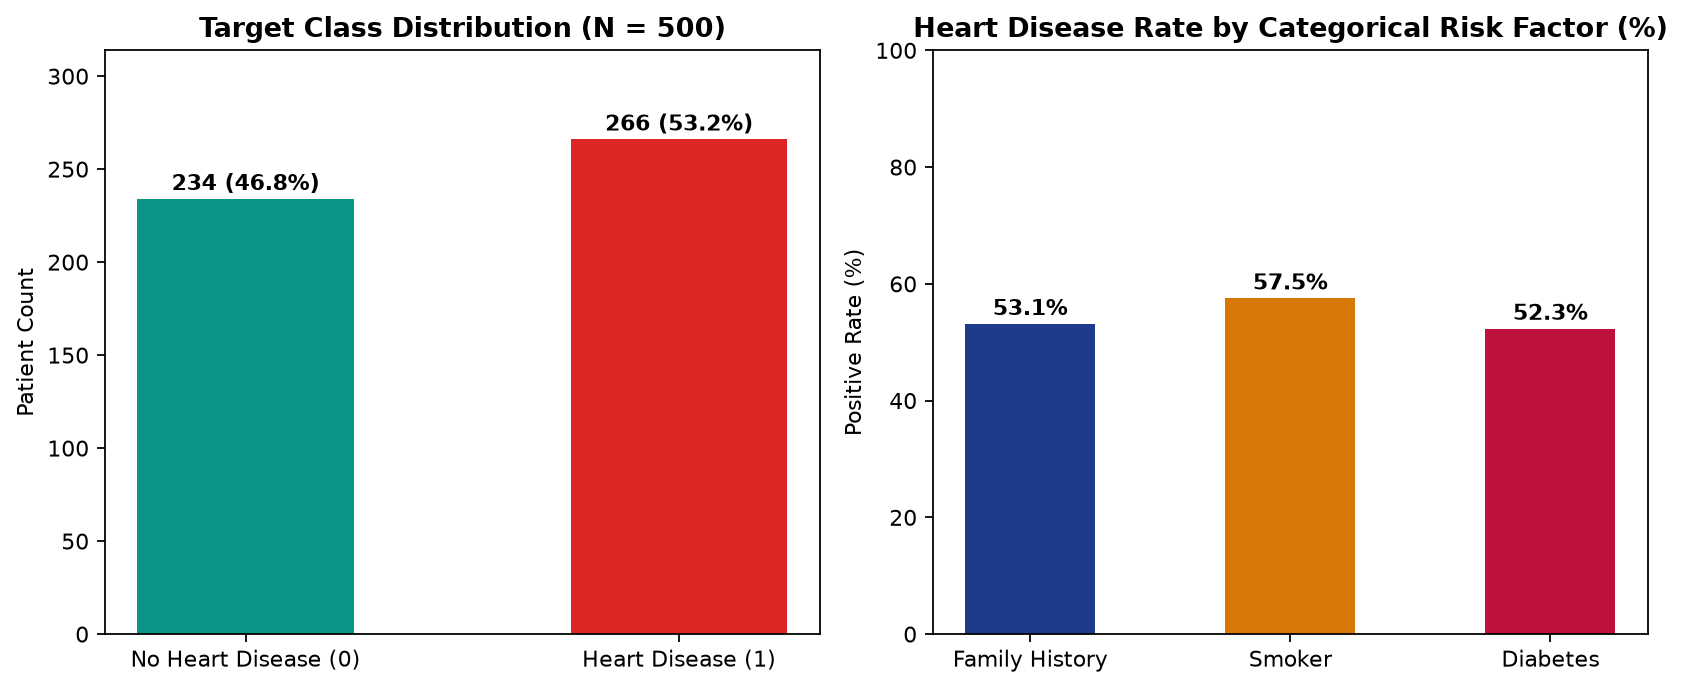

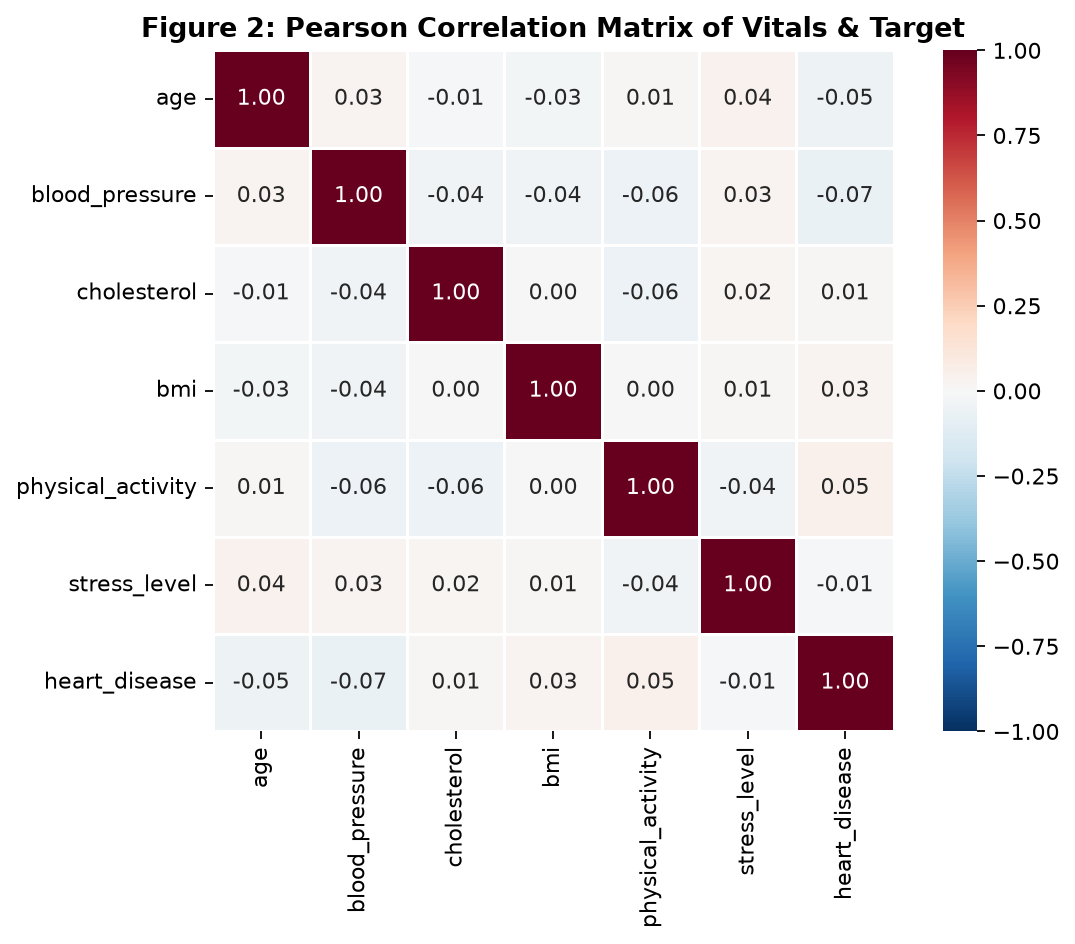

In [2]:
# Figure 1: Cohort Balance & Categorical Risk Factor Prevalence
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), dpi=160)
counts = df['heart_disease'].value_counts().sort_index()
b1 = axes[0].bar(['No Heart Disease (0)', 'Heart Disease (1)'], counts.values, color=['#0d9488', '#dc2626'], width=0.5)
axes[0].set_title(f'Target Class Distribution (N = {len(df)})', fontweight='bold')
axes[0].set_ylabel('Patient Count')
axes[0].set_ylim(0, max(counts.values) * 1.18)
for bar in b1:
    h = bar.get_height()
    axes[0].annotate(f'{int(h)} ({h/len(df)*100:.1f}%)', (bar.get_x()+bar.get_width()/2, h), xytext=(0,4), textcoords='offset points', ha='center', fontweight='bold')

prev = [df[df[c] == 'Yes']['heart_disease'].mean() * 100 for c in ['family_history', 'smoker', 'diabetes']]
b2 = axes[1].bar(['Family History', 'Smoker', 'Diabetes'], prev, color=['#1e3a8a', '#d97706', '#be123c'], width=0.5)
axes[1].set_title('Heart Disease Rate by Categorical Risk Factor (%)', fontweight='bold')
axes[1].set_ylabel('Positive Rate (%)')
axes[1].set_ylim(0, 100)
for bar in b2:
    h = bar.get_height()
    axes[1].annotate(f'{h:.1f}%', (bar.get_x()+bar.get_width()/2, h), xytext=(0,4), textcoords='offset points', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('heart_charts/fig1_cohort_prevalence.png', dpi=160)
plt.show()

# Figure 2: Pearson Correlation Matrix
corr_df = df[numerical_cols + ['heart_disease']].corr().round(2)
fig, ax = plt.subplots(figsize=(7.6, 6.0), dpi=160)
sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, linewidths=1.2, ax=ax)
ax.set_title('Figure 2: Pearson Correlation Matrix of Vitals & Target', fontweight='bold')
plt.tight_layout()
plt.savefig('heart_charts/fig2_correlation_matrix.png', dpi=160)
plt.show()

OLS Regression: blood_pressure = 0.0582 * age + 129.6797 | r = 0.0315 | R^2 = 0.0010


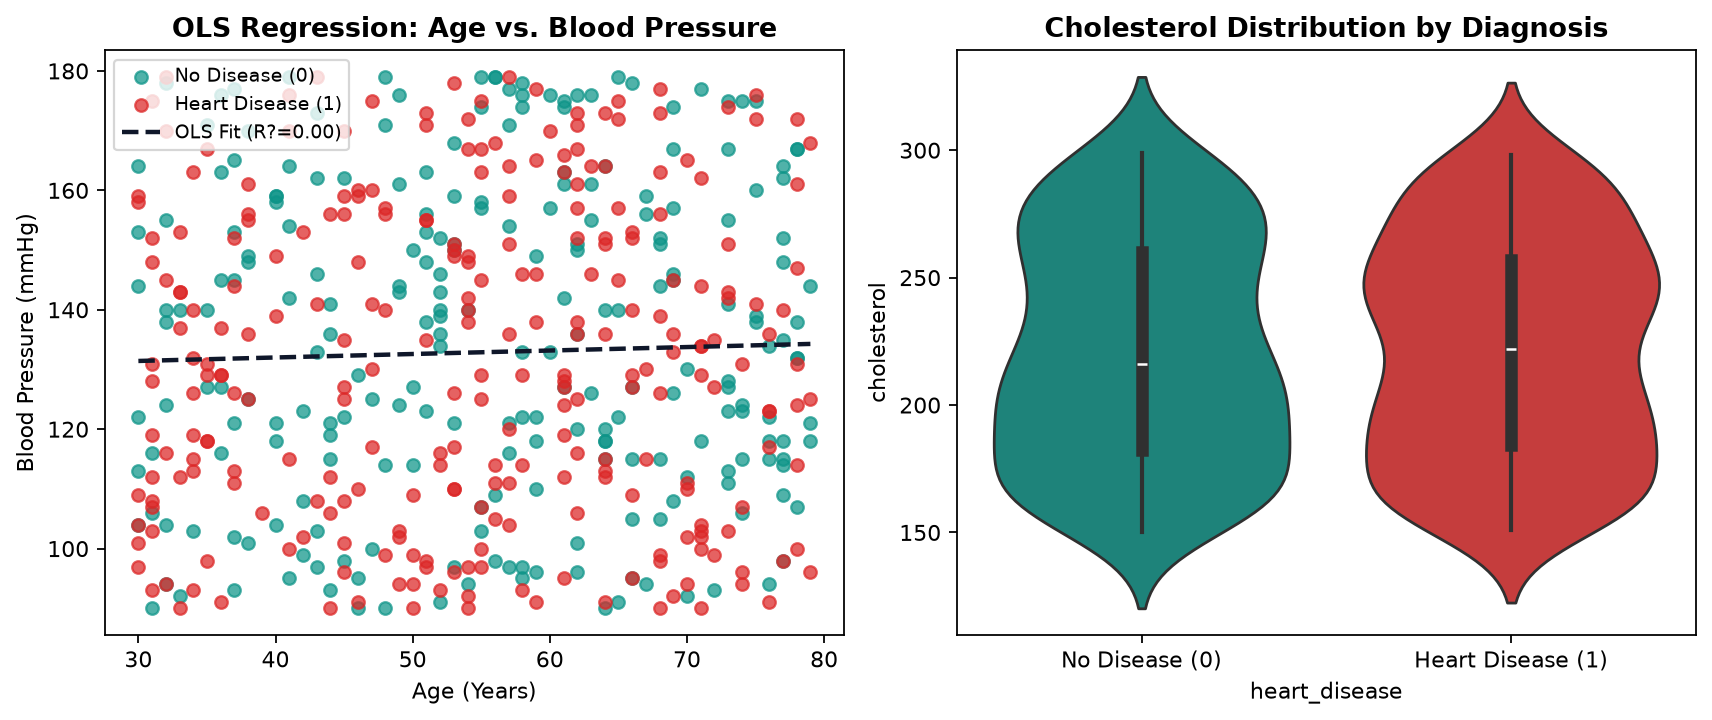

In [3]:
# Figure 3: OLS Regression (Age vs Blood Pressure) & Cholesterol Distribution
ols = LinearRegression().fit(df[['age']].values, df['blood_pressure'].values)
r2_bp = r2_score(df['blood_pressure'].values, ols.predict(df[['age']].values))
r_bp = df['age'].corr(df['blood_pressure'])
print(f'OLS Regression: blood_pressure = {ols.coef_[0]:.4f} * age + {ols.intercept_:.4f} | r = {r_bp:.4f} | R^2 = {r2_bp:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.6), dpi=160)
for val, col, lbl in [(0, '#0d9488', 'No Disease (0)'), (1, '#dc2626', 'Heart Disease (1)')]:
    sub = df[df['heart_disease'] == val]
    axes[0].scatter(sub['age'], sub['blood_pressure'], color=col, label=lbl, alpha=0.72, s=32)
x_age = np.linspace(df['age'].min(), df['age'].max(), 100).reshape(-1, 1)
axes[0].plot(x_age, ols.predict(x_age), color='#0f172a', linestyle='--', linewidth=2, label=f'OLS Fit (R?={r2_bp:.2f})')
axes[0].set_title('OLS Regression: Age vs. Blood Pressure', fontweight='bold')
axes[0].set_xlabel('Age (Years)'); axes[0].set_ylabel('Blood Pressure (mmHg)'); axes[0].legend(fontsize=8.5)

sns.violinplot(data=df, x='heart_disease', y='cholesterol', hue='heart_disease', palette=['#0d9488', '#dc2626'], inner='box', ax=axes[1], legend=False)
axes[1].set_title('Cholesterol Distribution by Diagnosis', fontweight='bold')
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(['No Disease (0)', 'Heart Disease (1)'])
plt.tight_layout()
plt.savefig('heart_charts/fig3_regression_vitals.png', dpi=160)
plt.show()

C:\Users\hp\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\hp\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\hp\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\hp\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\hp\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\hp\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


                  Model  Accuracy  Precision  Recall    F1  ROC_AUC  CV_Mean  CV_Std
Random Forest (Primary)      56.0      58.82   56.60 57.69    56.80     49.2    1.17
    Logistic Regression      55.0      55.56   75.47 64.00    50.46     52.2    4.83
       SVM (RBF Kernel)      58.0      59.32   66.04 62.50    58.57     52.8    4.45
              KNN (k=5)      50.0      52.73   54.72 53.70    47.69     48.4    3.32

Classification Report (Random Forest):
               precision    recall  f1-score   support

           0       0.53      0.55      0.54        47
           1       0.59      0.57      0.58        53

    accuracy                           0.56       100
   macro avg       0.56      0.56      0.56       100
weighted avg       0.56      0.56      0.56       100



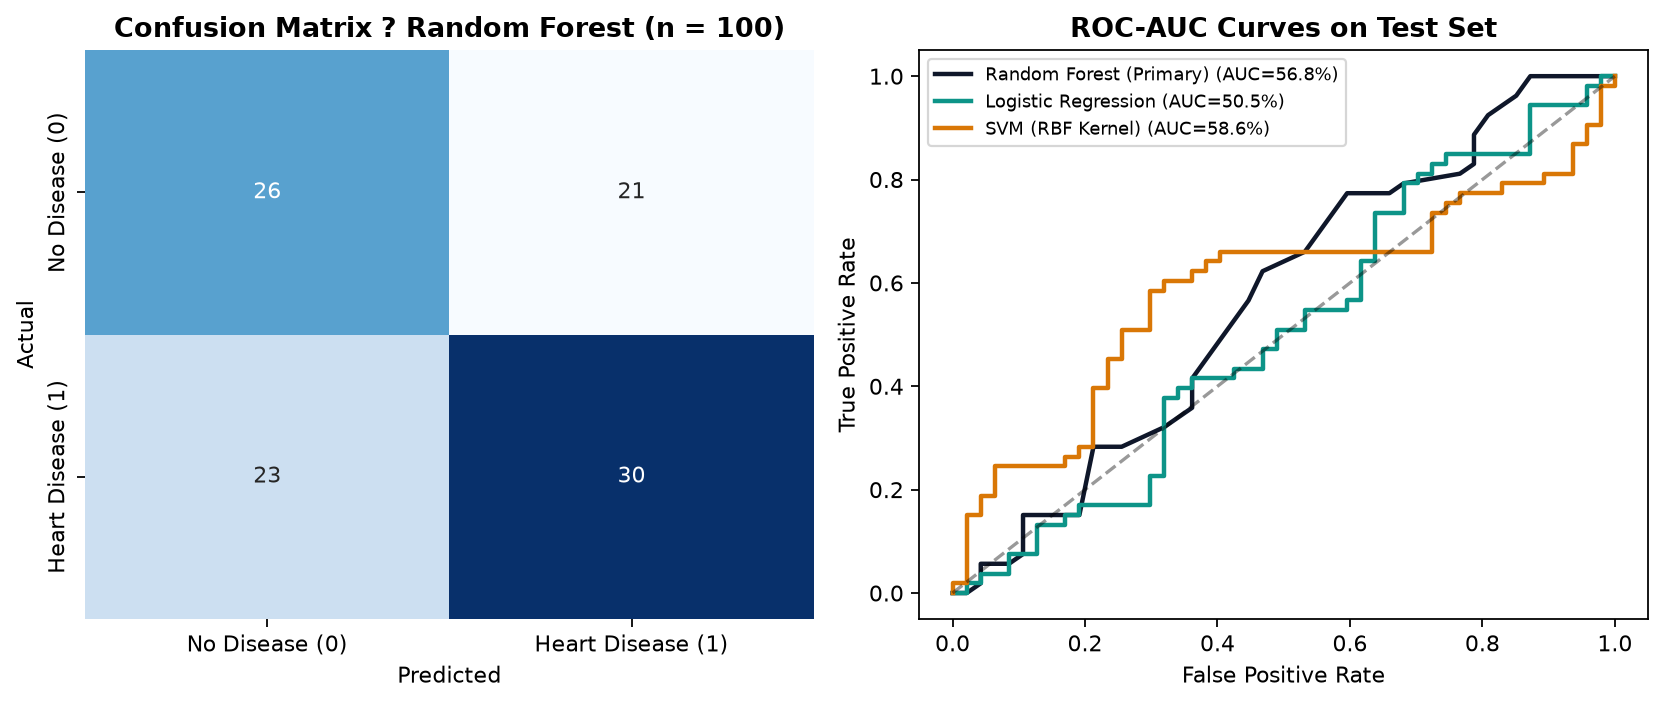

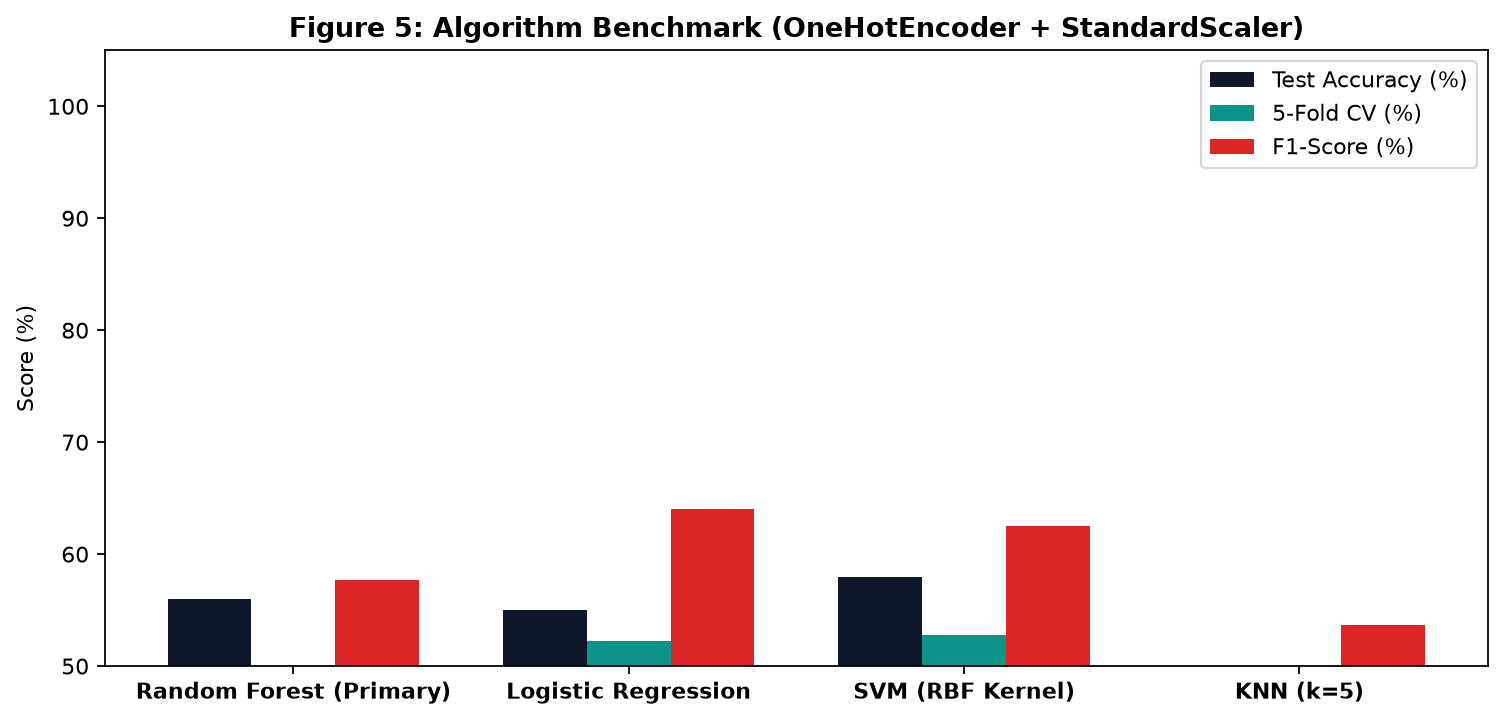

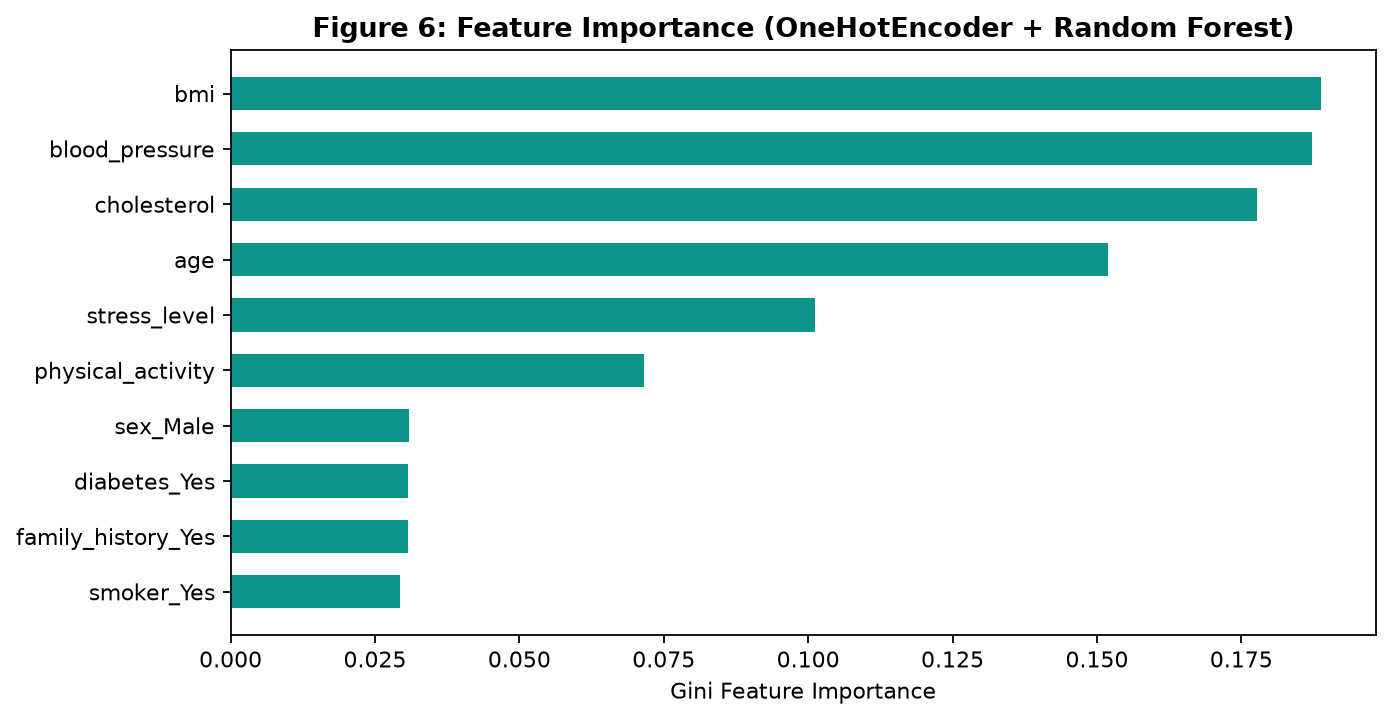

In [4]:
# OneHotEncoder + StandardScaler Pipeline, Evaluation Metrics & Model Comparison
X = df[numerical_cols + categorical_cols]
y = df['heart_disease']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
])

models = {
    'Random Forest (Primary)': RandomForestClassifier(n_estimators=100, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=500, random_state=42),
    'SVM (RBF Kernel)': SVC(kernel='rbf', probability=True, random_state=42),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
roc_data = {}
for name, clf in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('classifier', clf)])
    pipe.fit(X_train, y_train)
    yp = pipe.predict(X_test)
    yprob = pipe.predict_proba(X_test)[:, 1]
    cvs = cross_val_score(pipe, X, y, cv=cv, scoring='accuracy')
    rows.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, yp)*100, 2),
        'Precision': round(precision_score(y_test, yp)*100, 2),
        'Recall': round(recall_score(y_test, yp)*100, 2),
        'F1': round(f1_score(y_test, yp)*100, 2),
        'ROC_AUC': round(roc_auc_score(y_test, yprob)*100, 2),
        'CV_Mean': round(cvs.mean()*100, 2),
        'CV_Std': round(cvs.std()*100, 2)
    })
    roc_data[name] = (yprob, roc_auc_score(y_test, yprob)*100)
    if 'Random Forest' in name:
        rf_pipe, rf_pred = pipe, yp

res_df = pd.DataFrame(rows)
print(res_df.to_string(index=False))
print('\nClassification Report (Random Forest):\n', classification_report(y_test, rf_pred))

# Figure 4: Confusion Matrix & ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), dpi=160)
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Disease (0)', 'Heart Disease (1)'], yticklabels=['No Disease (0)', 'Heart Disease (1)'], ax=axes[0])
axes[0].set_title('Confusion Matrix ? Random Forest (n = 100)', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

for name, col in [('Random Forest (Primary)', '#0f172a'), ('Logistic Regression', '#0d9488'), ('SVM (RBF Kernel)', '#d97706')]:
    fpr, tpr, _ = roc_curve(y_test, roc_data[name][0])
    axes[1].plot(fpr, tpr, color=col, linewidth=2, label=f'{name} (AUC={roc_data[name][1]:.1f}%)')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[1].set_title('ROC-AUC Curves on Test Set', fontweight='bold')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig('heart_charts/fig4_confusion_roc.png', dpi=160)
plt.show()

# Figure 5: Model Comparison
fig, ax = plt.subplots(figsize=(9.5, 4.6), dpi=160)
x = np.arange(len(res_df)); w = 0.25
ax.bar(x - w, res_df['Accuracy'], w, label='Test Accuracy (%)', color='#0f172a')
ax.bar(x, res_df['CV_Mean'], w, label='5-Fold CV (%)', color='#0d9488')
ax.bar(x + w, res_df['F1'], w, label='F1-Score (%)', color='#dc2626')
ax.set_xticks(x); ax.set_xticklabels(res_df['Model'], fontweight='bold')
ax.set_ylim(50, 105); ax.set_ylabel('Score (%)'); ax.set_title('Figure 5: Algorithm Benchmark (OneHotEncoder + StandardScaler)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('heart_charts/fig5_model_comparison.png', dpi=160)
plt.show()

# Figure 6: Random Forest Feature Importance (with OneHotEncoded Columns)
ohe_names = numerical_cols + list(rf_pipe.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(categorical_cols))
imp = rf_pipe.named_steps['classifier'].feature_importances_
order = np.argsort(imp)
fig, ax = plt.subplots(figsize=(8.8, 4.6), dpi=160)
ax.barh(np.arange(len(order)), imp[order], color='#0d9488', height=0.6)
ax.set_yticks(np.arange(len(order))); ax.set_yticklabels([ohe_names[i] for i in order])
ax.set_xlabel('Gini Feature Importance'); ax.set_title('Figure 6: Feature Importance (OneHotEncoder + Random Forest)', fontweight='bold')
plt.tight_layout()
plt.savefig('heart_charts/fig6_feature_weights.png', dpi=160)
plt.show()